# Basic analysis: Xenium ovarian cancer

10x Xenium V1 human ovarian cancer, FFPE, base + add-on panel (480 genes). This notebook goes from the Xenium output bundle to a first-pass cell type annotation: QC and filtering, clustering, marker genes, a check on whether the three epithelial clusters are really different, and the final labels.

Two caches keep re-runs short:

- **`Xenium_..._outs.zarr`**: the SpatialData version of the raw output. The conversion only runs when the folder is missing.
- **`adata_processed_<settings>.h5ad`**: the filtered, normalised table with PCA, the neighbour graph, UMAP and Leiden labels. The file name includes the filtering and normalisation settings (currently `mc20_median`), so changing them never loads a stale checkpoint. When it exists, the notebook loads it and skips about 3 minutes of compute.
Set `RECOMPUTE = True` to rebuild it. `adata_processed.h5ad` and `adata_annotated.h5ad` are from an earlier run with a 10-transcript cutoff and 10,000-count scaling; they're kept for comparison.

PCA, neighbours, UMAP and Leiden run on the GPU through `rapids_singlecell` if it is installed (Linux or WSL2 only). Otherwise scanpy runs them on the CPU.

In [22]:
import warnings
warnings.filterwarnings("ignore")  # before the imports: dask and xarray_schema warn on import

import contextlib
import io
import logging
import os
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

import anndata as ad
import spatialdata as sd
from spatialdata_io import xenium
import scanpy as sc
import squidpy as sq

logging.getLogger("ome_zarr").setLevel(logging.ERROR)  # see the note under "Load"

try:
    import rapids_singlecell as rsc
    USE_GPU = True
except ImportError:
    USE_GPU = False

RECOMPUTE  = False  # rebuild the processed checkpoint even if it already exists
RUN_NAPARI = False  # the napari viewer blocks the kernel until its window is closed

MIN_COUNTS = 20     # transcripts per cell
MIN_CELLS  = 5      # cells per gene
TARGET_SUM = None   # None = scale every cell to the median transcript count

# Checkpoints are named after the settings, so changing them never loads a stale file.
# adata_processed.h5ad / adata_annotated.h5ad are the earlier run (MIN_COUNTS=10, TARGET_SUM=1e4).
_tag = f"mc{MIN_COUNTS}_{'median' if TARGET_SUM is None else f'{TARGET_SUM:g}'}"

xenium_path         = "./Xenium_V1_Human_Ovarian_Cancer_Addon_FFPE_outs"
zarr_path           = "./Xenium_V1_Human_Ovarian_Cancer_Addon_FFPE_outs.zarr"
h5ad_path           = f"./adata_processed_{_tag}.h5ad"
annotated_h5ad_path = f"./adata_annotated_{_tag}.h5ad"

_t0 = _last = time.time()

def step(name):
    """Print how long the work since the previous call took."""
    global _last
    now = time.time()
    print(f"{name}: {now - _last:.1f}s (total {now - _t0:.0f}s)")
    _last = now


def spatial_plot(adata, keys, *, palette=None, size=1.5, alpha=0.8):
    """Cells at their centroids, coloured by one or more obs columns.

    Categorical columns use the colours scanpy stored in adata.uns, so they match
    the UMAP. A dict palette maps category -> colour.
    """
    if isinstance(palette, dict):
        cats = adata.obs[keys].cat.categories
        palette = ListedColormap([palette.get(c, "#7f7f7f") for c in cats])
    with contextlib.redirect_stdout(io.StringIO()):
        sq.pl.spatial_scatter(
            adata, shape=None, color=keys, library_key="region",
            palette=palette, size=size, alpha=alpha, frameon=False, wspace=0.4,
        )


print(f"GPU backend: {'rapids_singlecell' if USE_GPU else 'not available, using scanpy on CPU'}")

GPU backend: not available, using scanpy on CPU


## Load

In [23]:
if not os.path.exists(zarr_path):
    sdata = xenium(xenium_path)
    sdata.write(zarr_path, overwrite=True)
    step("xenium -> zarr conversion")

sdata = sd.read_zarr(zarr_path)
step("zarr read")

use_checkpoint = os.path.exists(h5ad_path) and not RECOMPUTE
if use_checkpoint:
    adata = ad.read_h5ad(h5ad_path)
    print(f"Loaded {h5ad_path}; skipping QC metrics, filtering, normalisation and clustering")
else:
    adata = sdata.tables["table"].copy()
step("table ready")

zarr read: 1.7s (total 2s)
Loaded ./adata_processed_mc20_median.h5ad; skipping QC metrics, filtering, normalisation and clustering
table ready: 0.4s (total 2s)


## QC

Xenium includes negative-control probes (target sequences absent from human tissue) and unused codewords. Together they give an estimate of false-positive calls.

In [24]:
if not use_checkpoint:
    sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

raw = sdata.tables["table"]  # unfiltered, for numbers that should describe the whole run
gene_counts = raw.X.sum()
print(f"Negative control probes:    {raw.obs['control_probe_counts'].sum() / gene_counts:.4%} of gene counts")
print(f"Negative control codewords: {raw.obs['control_codeword_counts'].sum() / gene_counts:.4%} of gene counts")

Negative control probes:    0.0054% of gene counts
Negative control codewords: 0.0021% of gene counts


Background is very low (0.005% and 0.002%), so false-positive transcripts aren't something to worry about in this run.

The histograms show all cells before filtering. The red line marks the transcript cutoff used below.

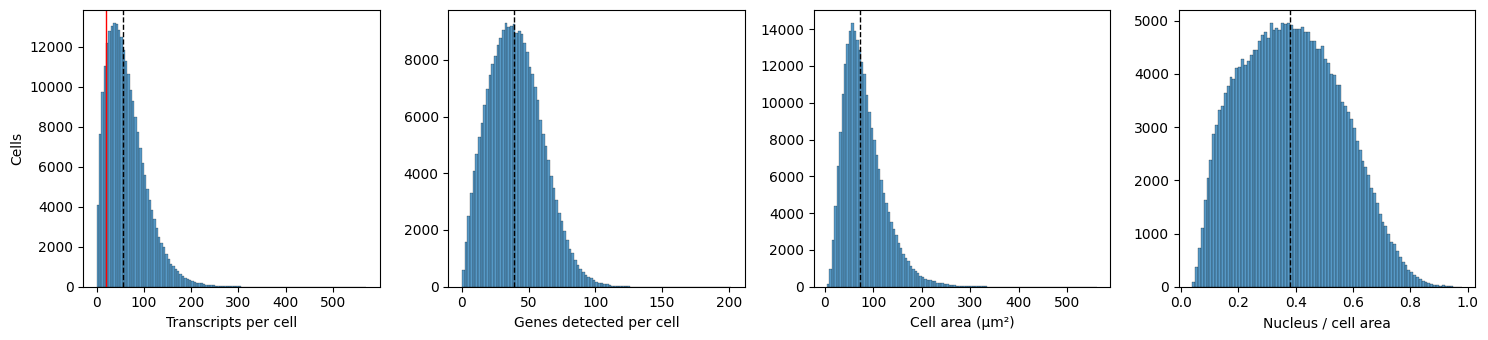

In [25]:
raw_counts = pd.Series(np.asarray(raw.X.sum(axis=1)).ravel(), index=raw.obs_names)
raw_genes  = pd.Series(np.asarray((raw.X > 0).sum(axis=1)).ravel(), index=raw.obs_names)

fig, axs = plt.subplots(1, 4, figsize=(15, 3.5))
panels = [  # (values, x label, bin width)
    (raw_counts,                                     "Transcripts per cell",    5),
    (raw_genes,                                      "Genes detected per cell", 2),
    (raw.obs["cell_area"],                           "Cell area (µm²)",         5),
    (raw.obs["nucleus_area"] / raw.obs["cell_area"], "Nucleus / cell area",     0.01),
]
for ax, (values, label, width) in zip(axs, panels):
    sns.histplot(values, binwidth=width, ax=ax)
    ax.axvline(values.median(), color="k", lw=1, ls="--")
    ax.set_xlabel(label)
    ax.set_ylabel("")
axs[0].axvline(MIN_COUNTS, color="r", lw=1)
axs[0].set_ylabel("Cells")
plt.tight_layout()
plt.show()

Dashed lines mark medians. The typical cell has about 55 transcripts from about 40 genes, which is normal for a 480-gene panel. Cell areas peak around 60 µm² with a long tail of large cells. The nucleus fraction is broad (0.05 to 0.9), as expected when segmentation expands cell boundaries a fixed distance beyond each nucleus.

In [26]:
if not use_checkpoint:
    sc.pp.filter_cells(adata, min_counts=MIN_COUNTS)
    sc.pp.filter_genes(adata, min_cells=MIN_CELLS)

print(f"Cells kept: {adata.n_obs:,} of {raw.n_obs:,} ({1 - adata.n_obs / raw.n_obs:.1%} removed)")
print(f"Genes kept: {adata.n_vars} of {raw.n_vars}")

Cells kept: 217,402 of 247,636 (12.2% removed)
Genes kept: 480 of 480


The 20-transcript cutoff removes 12% of cells. Every gene is detected in at least 5 cells, so all 480 stay.

An earlier run used a 10-transcript cutoff. It kept a cluster of about 24000 cells with a median of 22 transcripts, no usable markers and almost no ACTB (2% of cells, against 77 to 98% elsewhere). They sat along the tissue edges and looked like partial cells or segmentation fragments. At 20 transcripts most of those cells are gone.

## Normalisation and clustering

Raw counts are kept in `layers["counts"]`. Each cell is scaled to the median transcript count, then log-transformed. Scaling to the median (63) instead of the usual 10,000 matters with counts this low: at 10,000, a single transcript in a 60-count cell becomes a value of about 170 before the log, which exaggerates detected-vs-not and lets depth drive the clustering. That happened in an earlier run of this notebook: the two biggest clusters split on depth alone.

There is no highly-variable-gene step. The panel is 480 hand-picked genes, so all of them go into the PCA. This cell only does work when the checkpoint for the current settings is missing or `RECOMPUTE = True`.

In [27]:
if not use_checkpoint:
    adata.layers["counts"] = adata.X.copy()
    adata.uns["normalised_to"] = float(TARGET_SUM or np.median(adata.obs["total_counts"]))
    sc.pp.normalize_total(adata, target_sum=adata.uns["normalised_to"])
    sc.pp.log1p(adata)
    step("normalised")

    if USE_GPU:
        rsc.get.anndata_to_GPU(adata)
        rsc.pp.pca(adata)
        rsc.pp.neighbors(adata)
        rsc.tl.umap(adata)
        rsc.tl.leiden(adata, resolution=1.0, key_added="leiden")
        rsc.get.anndata_to_CPU(adata)
    else:
        sc.pp.pca(adata)
        sc.pp.neighbors(adata)
        sc.tl.umap(adata)
        sc.tl.leiden(adata, resolution=1.0, key_added="leiden", flavor="leidenalg", n_iterations=2)
    step(f"pca, neighbours, umap, leiden on {'GPU' if USE_GPU else 'CPU'}")

    adata.write(h5ad_path)
    step(f"checkpoint written to {h5ad_path}")

print(f"Counts scaled to {adata.uns['normalised_to']:g} per cell before log1p")
sizes = adata.obs["leiden"].value_counts()
print(f"Leiden, resolution 1.0: {len(sizes)} clusters")
print(f"Largest: {sizes.head(6).to_dict()}")
print(f"The other {len(sizes) - 6} hold {sizes.iloc[6:].sum()} cells in total (sizes {sizes.iloc[6:].min()} to {sizes.iloc[6:].max()})")

Counts scaled to 63 per cell before log1p
Leiden, resolution 1.0: 24 clusters
Largest: {'0': 64823, '1': 48370, '2': 37602, '3': 36929, '4': 18612, '5': 10329}
The other 18 hold 737 cells in total (sizes 3 to 387)


Leiden finds six large clusters plus a tail of tiny ones, the biggest with a few hundred cells and most with under 20. Clusters that small are too small to annotate. All of them are connected to the rest of the neighbour graph, so each cell in a cluster below 0.5% of the data is moved to the large cluster it has the strongest graph connections to. The original labels stay in `leiden_raw`.

In [28]:
MIN_CLUSTER_FRAC = 0.005

if "leiden_raw" not in adata.obs:
    adata.obs["leiden_raw"] = adata.obs["leiden"]
raw_lab = adata.obs["leiden_raw"].astype(str)
sizes = raw_lab.value_counts()
big = sorted(sizes[sizes >= MIN_CLUSTER_FRAC * adata.n_obs].index, key=int)
small = ~raw_lab.isin(big).values

# connection weight from each small-cluster cell to each large cluster
onehot = pd.get_dummies(raw_lab[~small]).reindex(columns=big, fill_value=0)
member = np.zeros((adata.n_obs, len(big)))
member[~small] = onehot.values
weight = adata.obsp["connectivities"][small] @ member
assert (weight.sum(axis=1) > 0).all(), "some small-cluster cells have no neighbours in a large cluster"

new_lab = raw_lab.values.copy()
new_lab[small] = np.array(big)[weight.argmax(axis=1)]
adata.obs["leiden"] = pd.Categorical(new_lab, categories=big)
adata.uns.pop("leiden_colors", None)

print(f"Reassigned {small.sum()} cells from {len(sizes) - len(big)} small clusters:")
print(pd.Series(new_lab[small]).value_counts().sort_index().to_string())
print("\nFinal cluster sizes:")
print(adata.obs["leiden"].value_counts().sort_index().to_string())

Reassigned 737 cells from 18 small clusters:
0    384
1    227
2     90
3     35
5      1

Final cluster sizes:
leiden
0    65207
1    48597
2    37692
3    36964
4    18612
5    10330


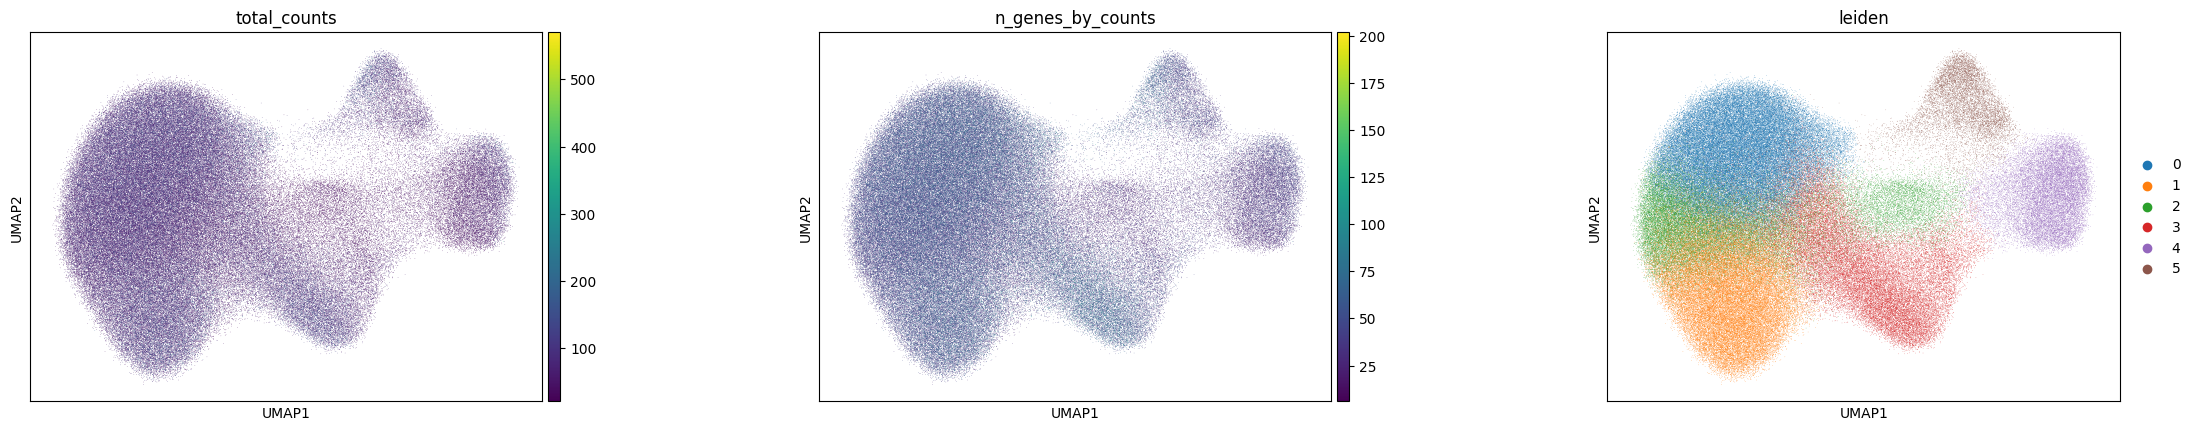

In [29]:
sc.pl.umap(adata, color=["total_counts", "n_genes_by_counts", "leiden"], wspace=0.4)

Six clusters after the clean-up. The epithelial clusters 0, 1 and 2 form one body on the left. Cluster 3 extends from it as a lobe, and 4 and 5 sit apart on the right. Cluster 2 comes in two parts, a strip inside the epithelial body and a smaller island between clusters 3 and 4.

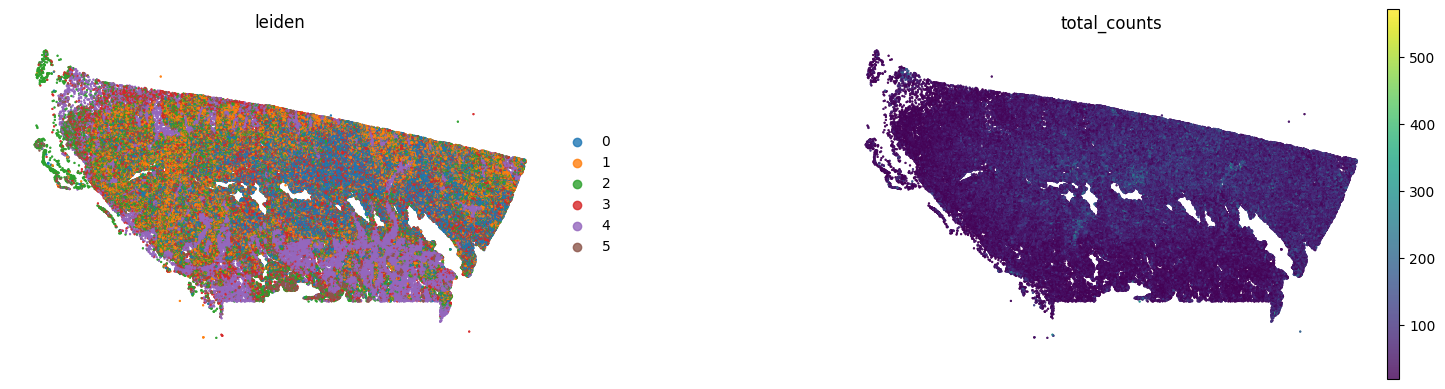

In [30]:
spatial_plot(adata, ["leiden", "total_counts"])

Cluster 4 fills the lower part of the section and the strands between the epithelial regions, which looks like stroma, and cluster 5 sits inside it. Clusters 0 and 1 fill the upper tumour region, with cluster 3 scattered throughout. Cluster 2 is concentrated along the tissue edges on the left, where the artifact cluster was in the earlier run.

In [31]:
if RUN_NAPARI:
    from loguru import logger
    logger.remove()
    from napari_spatialdata import Interactive

    interactive = Interactive(sdata)
    interactive.add_element("morphology_focus", "global")
    interactive.add_element("cell_labels", "global")
    interactive.run()

## Marker genes

Each cluster is tested against all other cells with a Wilcoxon test. `pts=True` stores the fraction of cells in each cluster that express each gene. A gene counts as a marker if it passes padj < 0.05 and logFC > 1, and is detected in more than 10% of the cluster's cells. Without the detection floor, rare genes with large fold changes make it into the list.

In [32]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon", key_added="rank_leiden", pts=True)
rg = sc.get.rank_genes_groups_df(adata, group=None, key="rank_leiden")
step("wilcoxon")

MAX_PADJ = 0.05
MIN_LFC  = 1.0
MIN_FRAC = 0.10
N_TOP    = 3

sig = rg[(rg["pvals_adj"] < MAX_PADJ) & (rg["logfoldchanges"] > MIN_LFC) & (rg["pct_nz_group"] > MIN_FRAC)]
top = sig.sort_values("scores", ascending=False).groupby("group", observed=True).head(N_TOP)
marker_genes = top["names"].drop_duplicates().tolist()

markers_per_cluster = (
    top.groupby("group", observed=True)["names"].apply(list)
       .reindex(adata.obs["leiden"].cat.categories)
       .apply(lambda g: g if isinstance(g, list) else [])  # clusters with no passing genes
)
print(markers_per_cluster.to_string())

wilcoxon: 21.8s (total 24s)
0      [ID4, IFITM3, ERBB3]
1    [MKI67, TUBA1B, CENPF]
2                        []
3        [CD74, APOE, CTSD]
4         [FN1, LUM, SPARC]
5     [IGFBP7, SPARC, RGS5]


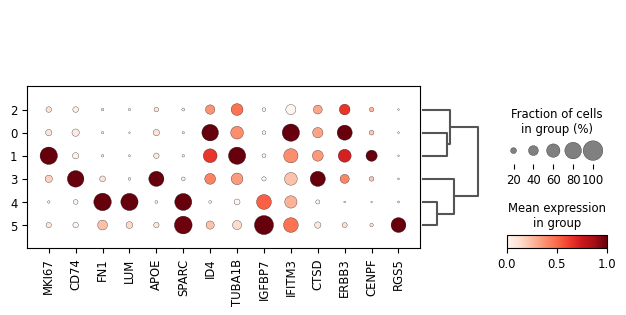

In [33]:
sc.tl.dendrogram(adata, groupby="leiden")
sc.pl.dotplot(
    adata, var_names=marker_genes, groupby="leiden",
    standard_scale="var", cmap="Reds", dendrogram=True,
)

The data-driven markers only show what is most specific. Known markers for the cell types expected in ovarian tumours are a useful cross-check, including the ones that turn out to be absent:

In [34]:
canonical = {
    "epithelial":   ["EPCAM", "KRAS", "SOX17", "ESR1"],
    "cycling":      ["MKI67", "TOP2A"],
    "immune":       ["PTPRC", "CD3E", "CD8A", "MS4A1"],
    "myeloid":      ["CD68", "CD163", "CD74", "APOE"],
    "endothelial":  ["PECAM1", "CD34"],
    "pericyte/SMC": ["RGS5", "NOTCH3", "ACTA2"],
    "fibroblast":   ["LUM", "DCN", "FN1", "SPARC"],
}
genes = [g for gs in canonical.values() for g in gs if g in adata.var_names]

detected = pd.DataFrame(
    adata[:, genes].layers["counts"].toarray() > 0, columns=genes, index=adata.obs_names
).groupby(adata.obs["leiden"], observed=True).mean()
print("Fraction of cells with at least one count:")
print(detected.round(2).to_string())

Fraction of cells with at least one count:
        EPCAM  KRAS  SOX17  ESR1  MKI67  TOP2A  PTPRC  CD3E  CD8A  MS4A1  CD68  CD163  CD74  APOE  PECAM1  CD34  RGS5  NOTCH3  ACTA2   LUM   DCN   FN1  SPARC
leiden                                                                                                                                                       
0        0.88  0.85   0.53  0.47   0.22   0.11   0.02  0.01  0.02   0.01  0.04   0.07  0.27  0.22    0.08  0.04  0.04    0.39   0.43  0.03  0.03  0.06   0.06
1        0.86  0.85   0.67  0.42   0.85   0.40   0.02  0.01  0.02   0.01  0.03   0.06  0.22  0.18    0.07  0.04  0.04    0.34   0.45  0.04  0.03  0.07   0.06
2        0.69  0.63   0.59  0.42   0.19   0.09   0.03  0.02  0.02   0.01  0.03   0.06  0.19  0.15    0.07  0.03  0.04    0.29   0.33  0.06  0.04  0.07   0.08
3        0.58  0.57   0.36  0.25   0.27   0.12   0.09  0.02  0.02   0.01  0.18   0.32  0.80  0.71    0.29  0.03  0.04    0.19   0.40  0.07  0.04  0.20   0.11
4        

- **0 and 1** are tumour epithelium: EPCAM and KRAS in 85 to 88% of cells, plus SOX17 and ESR1, which fits an ovarian serous origin. Cluster 1 adds MKI67 (85%) and TOP2A (40%), so it's the proliferating part of the tumour.
- **2** looks epithelial but is weaker on everything (EPCAM 69%), and no gene passes the marker filter.
- **3** is myeloid: CD74 80%, APOE 71%, CD163 32%. EPCAM also shows up in 58% of these cells. Since they sit inside the tumour region, that is most likely tumour transcripts assigned to them during segmentation, not real expression.
- **4** is fibroblasts: FN1 86%, LUM 84%, SPARC 83%, ACTA2 72%, consistent with CAFs.
- **5** is vascular: endothelial (PECAM1 54%, CD34 56%) and pericyte (RGS5 69%) markers in one cluster.
- Lymphocytes are essentially absent: PTPRC, CD3E, CD8A and MS4A1 are each in 1 to 9% of cells in every cluster. Either the section is immune-poor or those probes underperform. Worth checking against the morphology image before concluding either way.

## Are the three epithelial clusters different?

Clusters 0, 1 and 2 all express the epithelial genes. Before giving them separate labels, check whether they differ in anything besides depth.

In [35]:
obs = adata.obs.assign(nucleus_ratio=adata.obs["nucleus_area"] / adata.obs["cell_area"])
qc = obs.groupby("leiden", observed=True).agg(
    n_cells       = ("total_counts", "size"),
    median_counts = ("total_counts", "median"),
    p10_counts    = ("total_counts", lambda x: x.quantile(0.1)),
    median_genes  = ("n_genes_by_counts", "median"),
    median_area   = ("cell_area", "median"),
    nucleus_ratio = ("nucleus_ratio", "median"),
).round(2)
print(qc.to_string())

means = sc.get.aggregate(adata, by="leiden", func="mean")
corr = pd.DataFrame(np.corrcoef(means.layers["mean"]), index=means.obs_names, columns=means.obs_names)
print("\nPearson r between cluster mean profiles (log-normalised):")
print(corr.round(3).to_string())

        n_cells  median_counts  p10_counts  median_genes  median_area  nucleus_ratio
leiden                                                                              
0         65207           72.0        36.0          47.0        68.37           0.45
1         48597           71.0        33.0          45.0        74.46           0.43
2         37692           45.0        23.0          34.0        67.69           0.41
3         36964           63.0        28.0          45.0        75.46           0.36
4         18612           45.0        24.0          29.0       136.55           0.18
5         10330           64.0        28.0          40.0        87.33           0.29

Pearson r between cluster mean profiles (log-normalised):
       0      1      2      3      4      5
0  1.000  0.935  0.957  0.804  0.323  0.437
1  0.935  1.000  0.952  0.785  0.302  0.423
2  0.957  0.952  1.000  0.811  0.341  0.448
3  0.804  0.785  0.811  1.000  0.372  0.461
4  0.323  0.302  0.341  0.372  1.000  0.6

A high correlation between averages can hide real differences, and a depth gap can create differences that aren't real. The test below removes depth from the comparison. It takes cells from both clusters with at least 40 transcripts, randomly downsamples each to exactly 40, and compares again. Genes that still differ more than 2-fold at equal depth are real differences.

In [36]:
def depth_matched(adata, a, b, depth=40, seed=0):
    """Compare clusters a and b after downsampling every cell to the same depth."""
    keep = adata.obs["leiden"].isin([a, b]) & (adata.obs["total_counts"] >= depth)
    pair = ad.AnnData(
        X=adata.layers["counts"][keep.values].copy(),
        obs=adata.obs.loc[keep, ["leiden"]].copy(),
        var=pd.DataFrame(index=adata.var_names),
    )
    pair.obs["leiden"] = pair.obs["leiden"].cat.remove_unused_categories()
    sc.pp.downsample_counts(pair, counts_per_cell=depth, random_state=seed)
    sc.pp.log1p(pair)  # every cell now has exactly `depth` counts, so no further scaling

    r = np.corrcoef(sc.get.aggregate(pair, by="leiden", func="mean").layers["mean"])[0, 1]
    sc.tl.rank_genes_groups(pair, "leiden", groups=[b], reference=a, method="wilcoxon")
    de = sc.get.rank_genes_groups_df(pair, group=b)
    de = de[(de["pvals_adj"] < 0.05) & (de["logfoldchanges"].abs() > 1)]
    return r, pair.obs["leiden"].value_counts().to_dict(), de


for a, b in [("0", "1"), ("0", "2")]:
    r, n, de = depth_matched(adata, a, b)
    print(f"Cluster {b} vs {a}  (cells used: {n})")
    print(f"r at 40 transcripts per cell: {r:.3f}")
    print(f"genes with >2-fold difference: {len(de)}")
    if len(de):
        print(de.sort_values("logfoldchanges", ascending=False)[["names", "logfoldchanges"]].round(2).to_string(index=False))
    print()
step("depth-matched comparisons")

Cluster 1 vs 0  (cells used: {'0': 56577, '1': 40817})
r at 40 transcripts per cell: 0.932
genes with >2-fold difference: 12
 names  logfoldchanges
 MKI67            3.31
 TOP2A            2.45
 CENPF            2.23
 UBE2C            2.18
  CDK1            1.99
 CCNB2            1.91
TUBA1B            1.28
CDKN2C            1.26
 LTBP2           -1.09
S100A9           -1.15
   MGP           -1.22
 NPDC1           -1.26

Cluster 2 vs 0  (cells used: {'0': 56577, '2': 22129})
r at 40 transcripts per cell: 0.954
genes with >2-fold difference: 7
 names  logfoldchanges
   CD2            1.44
  SOS1            1.09
 SOX17            1.02
GPRC5A           -1.09
   MGP           -1.10
   ID4           -1.33
IFITM3           -1.50

depth-matched comparisons: 2.7s (total 27s)


**1 vs 0:** their depth is already the same (median 71 vs 72 transcripts). At 40 transcripts each, 12 genes still differ, led by a full cell-cycle program (MKI67, TOP2A, CENPF, UBE2C, CDK1, CCNB2). That's a biological split, so the two keep separate labels.

**2 vs 0:** 7 genes differ (ID4, IFITM3, GPRC5A and MGP lower in cluster 2; CD2, SOS1 and SOX17 higher), so cluster 2 isn't simply a low-depth copy of cluster 0. But its depth is lower (median 45), no gene marks it against all other cells, and it concentrates at the tissue edges. It's probably a mix of lower-quality epithelial cells and boundary cells with mixed signal, so its label below is tentative.

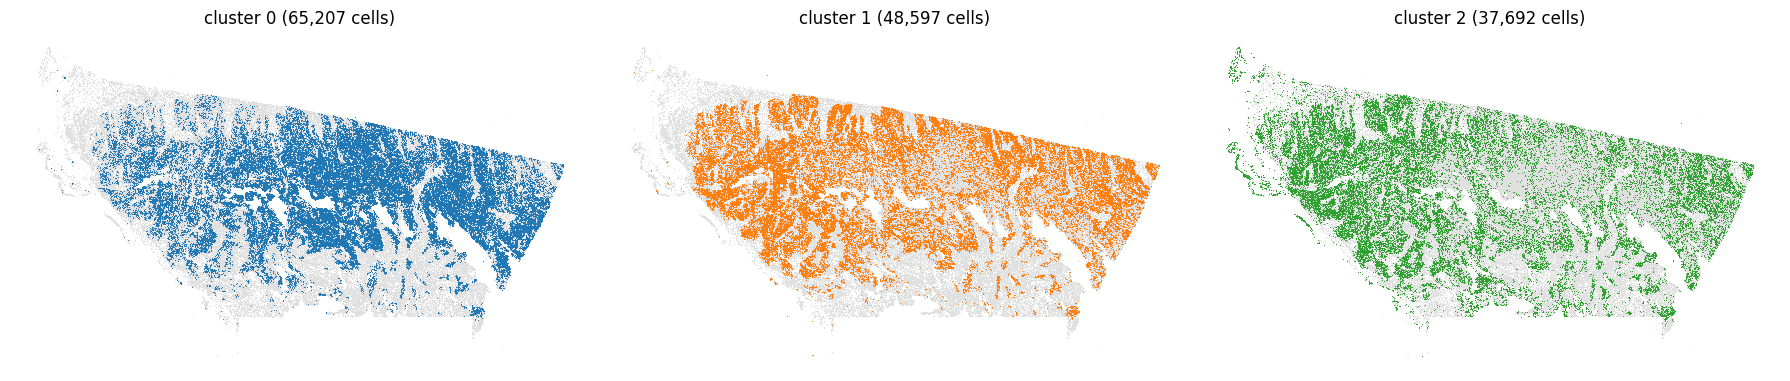

In [37]:
# One panel per cluster: overlaying them makes whichever is drawn last look dominant.
xy = np.asarray(adata.obsm["spatial"])[:, :2]
lab = adata.obs["leiden"].astype(str).values
colors = dict(zip(adata.obs["leiden"].cat.categories, adata.uns["leiden_colors"]))

fig, axs = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, cluster in zip(axs, ["0", "1", "2"]):
    ax.scatter(xy[:, 0], xy[:, 1], s=0.5, c="#e0e0e0", linewidths=0, rasterized=True)
    m = lab == cluster
    ax.scatter(xy[m, 0], xy[m, 1], s=0.5, c=colors[cluster], linewidths=0, rasterized=True)
    ax.set_title(f"cluster {cluster} ({m.sum():,} cells)")
    ax.set_aspect("equal")
    ax.invert_yaxis()
    ax.axis("off")
plt.tight_layout()
plt.show()

Clusters 0 and 1 both span the whole tumour region, with cycling cells (cluster 1) somewhat denser on the left. Proliferating cells spread through the tumour rather than gathered in one zone is the expected pattern. Cluster 2 is densest along the left edge and the outer boundary of the tissue.

## Annotation

| cluster | label | basis |
|---|---|---|
| 0 | Epithelial / Tumor | EPCAM 88%, KRAS 85%, SOX17, ESR1; top markers ID4, IFITM3, ERBB3 |
| 1 | Epithelial / Tumor, cycling | same epithelial genes plus MKI67 85%, TOP2A 40%; cell-cycle genes still differ from cluster 0 at equal depth |
| 2 | Epithelial (Low-count) | weaker epithelial profile, median 45 transcripts, no markers, concentrated at tissue edges; tentative |
| 3 | Macrophage / Myeloid | CD74 80%, APOE 71%, CTSD, CD163 32% |
| 4 | Fibroblast / CAF | FN1, LUM, SPARC in 83 to 86% of cells, ACTA2 72%; largest cells (137 µm²) with the smallest nucleus fraction (0.18) |
| 5 | Endothelial / Pericyte | PECAM1 54%, CD34 56%, RGS5 69%, IGFBP7 |

The labels are tied to the cluster IDs of the checkpointed run. If the clustering is recomputed, the IDs can change, so the next cell checks the cluster sizes first.

In [38]:
annotation_map = {
    "0": "Epithelial / Tumor",
    "1": "Epithelial / Tumor, cycling",
    "2": "Epithelial (Low-count)",
    "3": "Macrophage / Myeloid",
    "4": "Fibroblast / CAF",
    "5": "Endothelial / Pericyte",
}
annotated_sizes = {"0": 65_207, "1": 48_597, "2": 37_692, "3": 36_964, "4": 18_612, "5": 10_330}

if adata.obs["leiden"].value_counts().to_dict() != annotated_sizes:
    print("!! Cluster sizes differ from the run this annotation was made on. Re-check the map before trusting the labels.")

adata.obs["cell_type"] = adata.obs["leiden"].astype(str).map(annotation_map).astype("category")
assert adata.obs["cell_type"].notna().all(), "some clusters have no label"

pct = adata.obs["cell_type"].value_counts(normalize=True).mul(100).round(1)
print(pct.to_string())

cell_type
Epithelial / Tumor             30.0
Epithelial / Tumor, cycling    22.4
Epithelial (Low-count)         17.3
Macrophage / Myeloid           17.0
Fibroblast / CAF                8.6
Endothelial / Pericyte          4.8


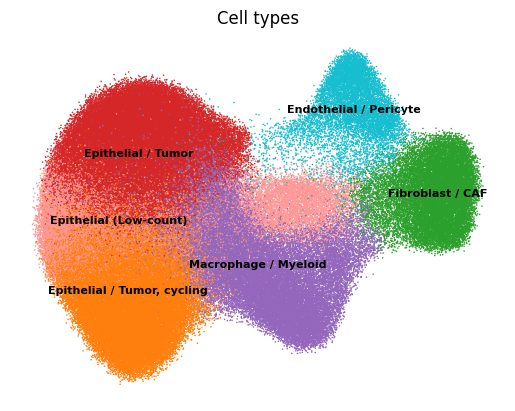

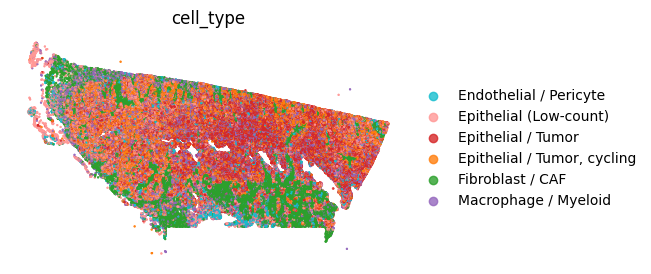

In [39]:
pal = {
    "Epithelial / Tumor":          "#d62728",
    "Epithelial / Tumor, cycling": "#ff7f0e",
    "Epithelial (Low-count)":      "#ff9896",
    "Macrophage / Myeloid":        "#9467bd",
    "Fibroblast / CAF":            "#2ca02c",
    "Endothelial / Pericyte":      "#17becf",
}

sc.pl.umap(adata, color="cell_type", palette=pal, size=5, legend_loc="on data",
           legend_fontsize=8, frameon=False, title="Cell types")
spatial_plot(adata, "cell_type", palette=pal)

Tumour epithelium makes up 70% of the cells kept (30% non-cycling, 22% cycling, 17% low-count), followed by macrophages at 17%, fibroblasts at 9% and vascular cells at 5%.

## Signature scores

A quick consistency check: score each cell on small gene sets and confirm each label scores highest on its own set. The genes overlap with the ones the labels were based on, so this checks that the labels were applied correctly. It isn't independent evidence that they're right.

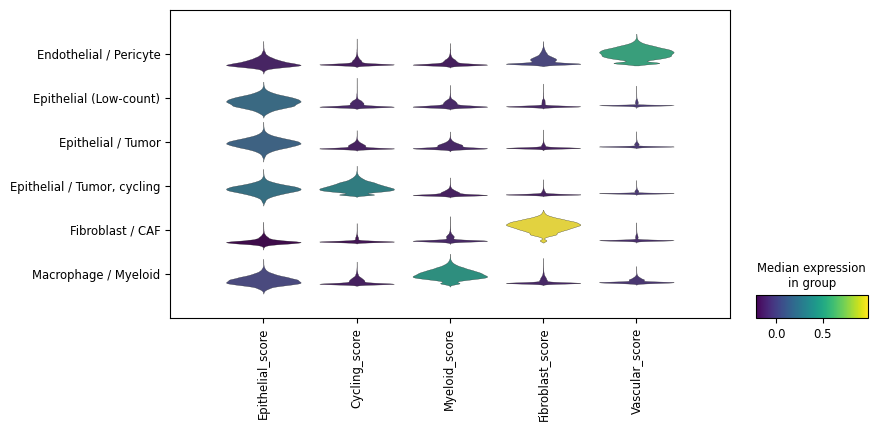

In [40]:
signatures = {
    "Epithelial":  ["EPCAM", "KRAS", "SOX17"],
    "Cycling":     ["MKI67", "TOP2A", "CENPF"],
    "Myeloid":     ["CD74", "APOE", "CD163"],
    "Fibroblast":  ["LUM", "DCN", "FN1"],
    "Vascular":    ["PECAM1", "CD34", "RGS5"],
}
for name, genes in signatures.items():
    sc.tl.score_genes(adata, [g for g in genes if g in adata.var_names], score_name=f"{name}_score")

vp = sc.pl.stacked_violin(
    adata, var_names=[f"{n}_score" for n in signatures], groupby="cell_type",
    cmap="viridis", figsize=(9, 4), return_fig=True,
)
vp.show()

Each label scores highest on its own signature. The cycling score is high only in the cycling tumour cells, the myeloid score in macrophages, the fibroblast score in CAFs and the vascular score in the endothelial/pericyte cluster. The low-count epithelial group scores about as high on the epithelial signature as the other tumour clusters and on nothing else. That supports calling it epithelial, but not much more.

In [41]:
adata.write(annotated_h5ad_path)

summary = adata.obs.groupby("cell_type", observed=True).agg(
    n_cells       = ("total_counts", "size"),
    median_counts = ("total_counts", "median"),
    median_genes  = ("n_genes_by_counts", "median"),
)
summary.insert(1, "pct", (summary["n_cells"] / adata.n_obs * 100).round(1))
print(f"Saved {annotated_h5ad_path}\n")
print(summary.to_string())
step("done")

Saved ./adata_annotated_mc20_median.h5ad

                             n_cells   pct  median_counts  median_genes
cell_type                                                              
Endothelial / Pericyte         10330   4.8           64.0          40.0
Epithelial (Low-count)         37692  17.3           45.0          34.0
Epithelial / Tumor             65207  30.0           72.0          47.0
Epithelial / Tumor, cycling    48597  22.4           71.0          45.0
Fibroblast / CAF               18612   8.6           45.0          29.0
Macrophage / Myeloid           36964  17.0           63.0          45.0
done: 14.6s (total 41s)
